## **Milestone 1**
**Project Title: Modern Recession Detector**

**Names: Preston Bukaske, Mason Mitchell**


The partners for this project are Preston Bukaske and Mason Mitchell. To answer our question on whether traditional economic indicators are still reliable predictors of U.S. recessions or not, we want to look at various factors, such as unemployment, consumer activity/confidence, defaults, debts, government spending, and GDP growth rate. We want to see if factors such as these can still reliably predict recessions or not.

Collaboration plan: We plan on meeting two to three times a week to go over the project, ideally over weekends. During these meetings, we will review our progress and decide the current demands of the projects and then divide the workloads based on our own expertise. The technologies we plan on using are primarily going to be Google Docs for collaborative explanations, GitHub to push our changes, and PyNotebooks to process and administer the data.



**Our Data Sets**

Rather than just discussing the data sets, we want to also show you the sets we're working with. But before we do this, we need to use some ETL to make sure it's ready to be presented. We're going to start with the first step for our first file: Export.

In [ ]:
%cd /content
!git clone https://github.com/masonmemelord/Data-Science-Final.git
%cd /content/Data-Science-Final/DataFiles
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

/content
Cloning into 'Data-Science-Final'...
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (7/7), done.
remote: Total 9 (delta 1), reused 9 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (9/9), 9.83 KiB | 3.28 MiB/s, done.
Resolving deltas: 100% (1/1), done.
/content/Data-Science-Final/DataFiles


**Data Set #1**
**https://fred.stlouisfed.org/series/FEDFUNDS**


Our first set is also on FRED, where we have the federal funds effective rates. This is essentially the interest rate where depository institutions trade federal funds with each other. We want to pay attention to this because  it influences other interest rates like prime rate and, it also indirectly influences longer-term interest rates such as mortgages, loans, and savings. Smaller federal funds effective rates are traditionally linked to a recession, as less borrowing means less economic activity. A question we hope to answer using this set is do federal funds rates have a correlation between previous recessions, or is it unrelated?

In [ ]:


firstdf = pd.read_csv("FEDFUNDS.csv", parse_dates=["observation_date"]) #Opens
#the FEDFUNDS file for us to read into, and we parse the dates of
#observation_date because it turns the numbers of the string into readable dates
firstdf #displays to confirm that it has been successfully read

,observation_date,FEDFUNDS
0,1954-07-01,0.80
1,1954-08-01,1.22
2,1954-09-01,1.07
3,1954-10-01,0.85
4,1954-11-01,0.83
...,...,...
862,2026-05-01,3.63
863,2026-06-01,3.63
864,2026-07-01,3.63
865,2026-08-01,3.63


From here, we see that we have too many rows. We want to shrink that option from 2020 to represent everything from 2020 and onwards. Through the various changes in the world after COVID, we mainly want to focus on the post-COVID changes, so we should transform this set by reducing the scope.

    observation_date  FEDFUNDS
789       2020-04-01      0.05


Text(0, 0.5, 'Rate (in %)')

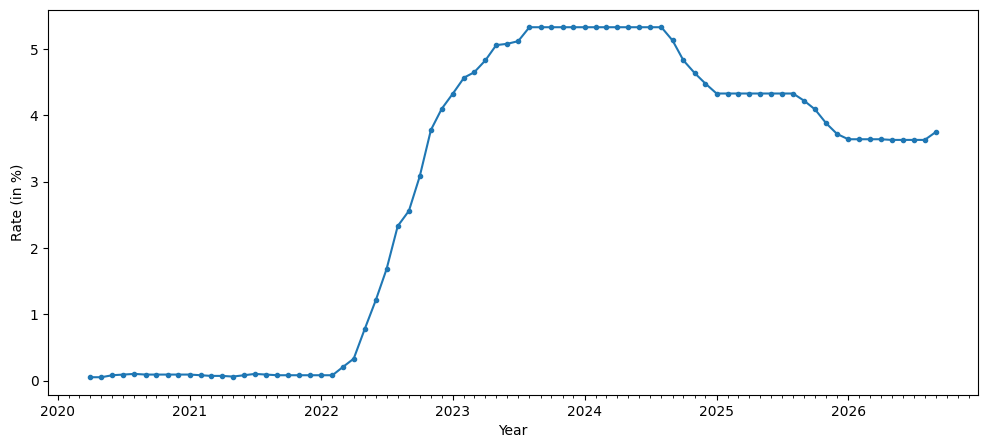

In [ ]:
import matplotlib.dates as dates #We're working with dates, so we want to import
#this library


postCovid = firstdf[firstdf["observation_date"] == "2020-04-01"] #We know that
#the covid recession ended in April of 2020, so we want to start looking at
#the data from there to the present. We see that this starts at index 789,
#so we're looking at 789 and beyond.
postCovid = firstdf[789:] #Only includes the federal funds from April of 2020
#and beyond

fig, ax = plt.subplots(figsize=(12,5)) #Creates the plot for us to work with,
#where fig is the size of our graph and ax is our actual points in the graph
ax.plot(postCovid["observation_date"], postCovid["FEDFUNDS"],
        marker="o", markersize=3)#Plots our observation dates on the x axis,
# and the actual federal funds as the y axis

ax.xaxis.set_minor_locator(dates.MonthLocator()) #We may want to pay attention
#to particular months to check recession patterns, so we make sure the months
#are tracked using this

ax.set_xlabel("Year") #Sets the x axis to be year
ax.set_ylabel("Rate (in %)") #Sets the y axis to be the federal funds effective
#rates

**INTERESTING STATS:**

In [ ]:
print(postCovid["FEDFUNDS"].mean()) #From here, we see that the average federal
#effective funds rates after covid is around 2.9%
print(postCovid["FEDFUNDS"].min()) #At the lowest point after covid, the federal
#effective funds rate has reached 0.05%
print(postCovid["FEDFUNDS"].max()) #Since after covid, the highest the federal
#effective fund rates have been was 5.33%

2.9138461538461535
0.05
5.33


Now, we have a transformed data set through ETL where we have a graph and some interesting stats. This wasn't easy. Some of the challenges we've experienced was working with the dates. It was difficult to obtain a proper x-axis, since there were hundreds of entries where the time was only based on the month. To resolve this, we had to use the dates extension of matplotlib to make the graphs go by year rather than months.

Now that's one of our data sets. We still have two more.

**Data Set #2**
**https://fred.stlouisfed.org/series/UNRATE**

Our second set is from FRED where we have the monthly national unemployment rate from 1948 to today. This data is restricted to people of ages 16 and higher and who reside in the 50 states or District of Columbia, but it gives the calculated percentage of the labor force that’s currently unemployed. A question we hope to answer with this set is can we use trends in unemployment rates to detect a correlation between recessions that have happened, or are they unrelated?


In [ ]:
seconddf= pd.read_csv("UNRATE.csv", parse_dates=["observation_date"]) #Opens
#the unemployment rate file for us to view and parses the dates so we can work
#with them later
seconddf #prints the dataframe for us to see

,observation_date,UNRATE
0,1948-01-01,3.4
1,1948-02-01,3.8
2,1948-03-01,4.0
3,1948-04-01,3.9
4,1948-05-01,3.5
...,...,...
940,2026-05-01,4.3
941,2026-06-01,4.2
942,2026-07-01,4.1
943,2026-08-01,4.1


Just like with the last set, we're going to do some ETL to transform the data.

Text(0, 0.5, 'Rate (in %)')

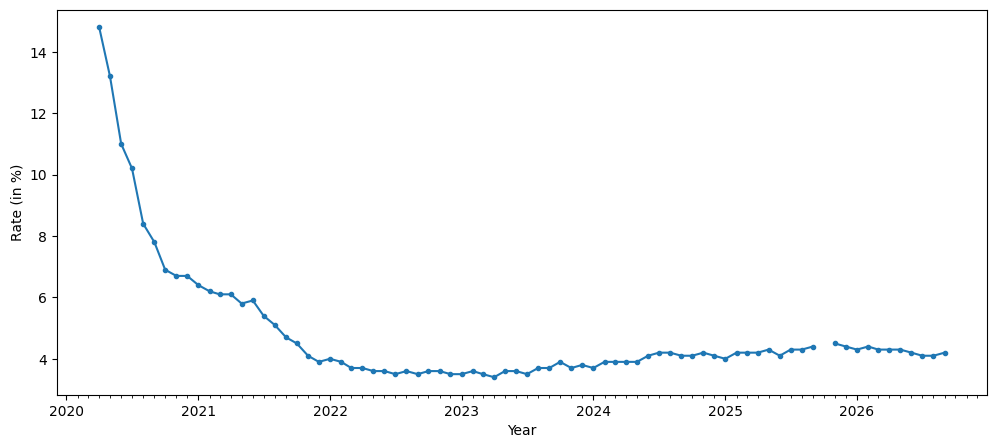

In [ ]:
afterCovid = seconddf[seconddf["observation_date"] == "2020-04-01"] #We know that
#the covid recession ended in April of 2020, so we want to start looking at
#the data from there to the present. We see that this starts at index 867,
#so we're looking at 867 and beyond.
afterCovid = seconddf[867:] #Only includes the unemployment rates
#from April of 2020 and beyond
fig, ax = plt.subplots(figsize=(12,5)) #Creates the plot for us to work with,
#where fig is the size of our graph and ax is our actual points in the graph
ax.plot(afterCovid["observation_date"], afterCovid["UNRATE"],
        marker="o", markersize=3)#Plots our observation dates on the x axis,
# and the actual unemployment rate as the y axis
ax.xaxis.set_major_locator(dates.YearLocator())
ax.xaxis.set_minor_locator(dates.MonthLocator()) #We may want to pay attention
#to particular months to check recession patterns, so we make sure the months
#are tracked using this

ax.set_xlabel("Year") #Sets the x axis to be year
ax.set_ylabel("Rate (in %)") #Sets the y axis to be the unemployment rates


**INTERESTING STATS**

In [ ]:
print(afterCovid["UNRATE"].mean()) #From here, we see that since covid,
#the average unemployment was around 4.8%
print(afterCovid["UNRATE"].min()) #On this line, we can determine that
#at its lowest, the unemployment rate after covid reached 3.4%
print(afterCovid["UNRATE"].max()) #Through this line, we can determine that
#at its highest, the unemployment rate after covid reached 14.8%

4.812987012987013
3.4
14.8


Like the previous set, while we also struggled with the dates on this one, our main issue was the gap between data in the two sets at around October 2025. We tried to understand and eliminate this, but it was mainly a misunderstanding for the time and context of the data. This was because of the government shut down. So naturally, all government activity was absent. It was mainly a historical misunderstanding.

That aside, for our third data set, we'll do the same thing as the last two.

**Data Set #3**
**https://fred.stlouisfed.org/series/RRSFS**

Our third set is from FRED where we have the advance real retail and food service sales. This set has two series to represent this data, and it goes from 1992 to 2026. A question we hope to answer using this data set is real retail and food services sales correlated to previous recessions?



In [ ]:
thirddf= pd.read_csv("RRSFS.csv", parse_dates=["observation_date"])
thirddf

,observation_date,RRSFS
0,1992-01-01,115095.0
1,1992-02-01,114855.0
2,1992-03-01,114052.0
3,1992-04-01,114721.0
4,1992-05-01,114868.0
...,...,...
411,2026-04-01,228364.0
412,2026-05-01,229413.0
413,2026-06-01,231107.0
414,2026-07-01,229697.0


And to transform and to get a graph:

Text(0, 0.5, 'Money (in millions)')

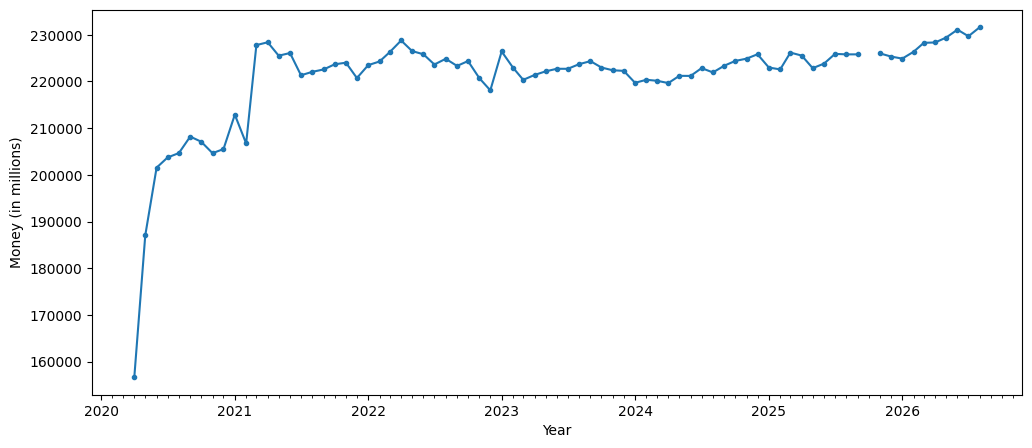

In [ ]:
sinceCovid = thirddf[thirddf["observation_date"] == "2020-04-01"] #We know that
#the covid recession ended in April of 2020, so we want to start looking at
#the data from there to the present. We see that this starts at index 339,
#so we're looking at 339 and beyond.

sinceCovid = thirddf[339:] #Only includes the retail and food service sales
#from April of 2020 and beyond
fig, ax = plt.subplots(figsize=(12,5)) #Creates the plot for us to work with,
#where fig is the size of our graph and ax is our actual points in the graph
ax.plot(sinceCovid["observation_date"], sinceCovid["RRSFS"],
        marker="o", markersize=3)#Plots our observation dates on the x axis,
# and the millions of CPI adjusted dollars as the y axis
ax.xaxis.set_major_locator(dates.YearLocator())
ax.xaxis.set_minor_locator(dates.MonthLocator()) #We may want to pay attention
#to particular months to check recession patterns, so we make sure the months
#are tracked using this

ax.set_xlabel("Year") #Sets the x axis to be year
ax.set_ylabel("Money (in millions)") #Sets the y axis to be the millions
# of CPI adjusted dollars.

**INTERESTING STATS**

In [ ]:
print(sinceCovid["RRSFS"].mean()) #From here, we see that after Covid,
#the average retail and food service sales was around $220,711 million dollars
print(sinceCovid["RRSFS"].min()) #From this line, we can determine that
#at its lowest, the retail and food service sales reached $156,632 million
print(sinceCovid["RRSFS"].max()) #Through this line, we can see that
#at its highest, the retail and food service sales reached $231,630 million

220711.69736842104
156632.0
231630.0


That aside, we now have our third set transformed with a graph and some interesting stats. The challenges we had working with it was, like with the other sets, working with the dates. We had to take time to learn and understand the dates extension with matplotlib. It was too difficult to try to splice the dates on their own, so we had to go learn new commands and syntax to be able to properly transform the data into a viewable graph.